In [2]:
!nvidia-smi
!nvcc --version | tail -2

Sun Nov  1 08:08:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
!apt-get -qq update
!apt-get -qq install -y redis-server > /dev/null
!pip -q install fastapi "uvicorn[standard]" httpx redis huggingface_hub psutil pandas matplotlib
print("Cài đặt xong")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Cài đặt xong


In [4]:
%%bash
set -e
cd /content
[ -d llama.cpp ] || git clone --depth 1 https://github.com/ggml-org/llama.cpp
cd llama.cpp
CAP=$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader | head -1 | tr -d '.')
[ -z "$CAP" ] && CAP=75
echo "GPU compute capability: $CAP"
cmake -B build -DGGML_CUDA=ON -DCMAKE_CUDA_ARCHITECTURES=$CAP -DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release
cmake --build build --config Release -j$(nproc) --target llama-server
ls -la build/bin/llama-server

GPU compute capability: 75
-- The C compiler identification is GNU 13.3.0
-- The CXX compiler identification is GNU 13.3.0
-- Detecting C compiler ABI info
-- Detecting C compiler ABI info - done
-- Check for working C compiler: /usr/bin/cc - skipped
-- Detecting C compile features
-- Detecting C compile features - done
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/c++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- llama.cpp version: 0.8.0-dev
-- Found Git: /usr/bin/git (found version "2.43.0")
-- The ASM compiler identification is GNU
-- Found assembler: /usr/bin/cc
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD - Success
-- Found Threads: TRUE
-- Warning: ccache not found - consider installing it for faster compilation or disable this warning with GGML_CCACHE=OFF
-- CMAKE_SYSTEM_PROCESSOR: x86_64
-- GGML_SYSTEM_ARCH: x86
-- Found O

Cloning into 'llama.cpp'...
Updating files: 100% (4015/4015), done.
CMAKE_BUILD_TYPE=Release


In [5]:
import os
from huggingface_hub import hf_hub_download

REPO = "second-state/Qwen2.5-3B-Instruct-GGUF"
FILES = {
    "fp16": "Qwen2.5-3B-Instruct-f16.gguf",
    "q8":   "Qwen2.5-3B-Instruct-Q8_0.gguf",
    "q4":   "Qwen2.5-3B-Instruct-Q4_K_M.gguf",
}
MODELS = {}
for key, fname in FILES.items():
    MODELS[key] = hf_hub_download(repo_id=REPO, filename=fname, local_dir="/content/models")
    print(f"{key:5s} {os.path.getsize(MODELS[key])/1e9:5.2f} GB  {MODELS[key]}")

Qwen2.5-3B-Instruct-f16.gguf: reconstructing file:   0%|          |  0.00B / 6.18GB            

Qwen2.5-3B-Instruct-f16.gguf: downloading bytes:           |  0.00B            

fp16   6.18 GB  /content/models/Qwen2.5-3B-Instruct-f16.gguf


Qwen2.5-3B-Instruct-Q8_0.gguf: reconstructing file:   0%|          |  0.00B / 3.29GB            

Qwen2.5-3B-Instruct-Q8_0.gguf: downloading bytes:           |  0.00B            

q8     3.29 GB  /content/models/Qwen2.5-3B-Instruct-Q8_0.gguf


Qwen2.5-3B-Instruct-Q4_K_M.gguf: reconstructing file:   0%|          |  0.00B / 1.93GB            

Qwen2.5-3B-Instruct-Q4_K_M.gguf: downloading bytes:           |  0.00B            

q4     1.93 GB  /content/models/Qwen2.5-3B-Instruct-Q4_K_M.gguf


In [7]:
import json, shutil
from google.colab import files

up = files.upload()
name = [n for n in up.keys() if n.lower().endswith(".json")][0]
shutil.copy(name, "/content/menu 1.json")
print("Đã nhận:", name)

Saving menu 1.json to menu 1 (1).json
Đã nhận: menu 1 (1).json


In [8]:
with open("/content/menu 1.json", encoding="utf-8") as f:
    menu = json.load(f)

def vnd(x):
    return f"{x:,}".replace(",", ".") + "đ"

cat = menu["categories"]
lines = []
lines.append(
    f"Bạn là nhân viên tư vấn và nhận đơn của quán {menu['shop_name']}. "
    "Chỉ dùng thông tin trong MENU bên dưới, không bịa món, không bịa giá. "
    "Trả lời ngắn gọn, thân thiện bằng tiếng Việt. "
    "Khi khách đặt món, tính tổng tiền = (giá món + phụ thu size + giá topping) x số lượng và nêu rõ cách tính."
)
lines.append("\nSIZE: " + ", ".join(f"{k} (+{vnd(v)})" for k, v in menu["sizes"].items()) + ". Món bánh không có size.")
lines.append("\nMÓN BÁN CHẠY: " + ", ".join(
    next(i["name"] for i in menu["items"] if i["id"] == b) for b in menu["bestsellers_seed"]))
lines.append("\nMENU:")
for it in menu["items"]:
    size_txt = "có size M/L" if it["sized"] else "không có size"
    allergens = ", ".join(it["allergens"]) if it["allergens"] else "không"
    caf = "có" if it["caffeine"] else "không"
    lines.append(f"- {it['name']} [{cat[it['category']]}] {vnd(it['price'])} ({size_txt}). {it['description']} Dị ứng: {allergens}. Caffeine: {caf}.")
lines.append("\nTOPPING:")
for t in menu["toppings"]:
    allergens = ", ".join(t["allergens"]) if t["allergens"] else "không"
    lines.append(f"- {t['name']}: +{vnd(t['price'])}, dùng cho: {', '.join(cat[c] for c in t['categories'])}. Dị ứng: {allergens}.")

SYSTEM_PROMPT = "\n".join(lines)
with open("/content/system_prompt.txt", "w", encoding="utf-8") as f:
    f.write(SYSTEM_PROMPT)

print(SYSTEM_PROMPT[:1500], "\n...")
print("\nSố ký tự:", len(SYSTEM_PROMPT))

Bạn là nhân viên tư vấn và nhận đơn của quán Hallelujah Coffee. Chỉ dùng thông tin trong MENU bên dưới, không bịa món, không bịa giá. Trả lời ngắn gọn, thân thiện bằng tiếng Việt. Khi khách đặt món, tính tổng tiền = (giá món + phụ thu size + giá topping) x số lượng và nêu rõ cách tính.

SIZE: M (+0đ), L (+10.000đ). Món bánh không có size.

MÓN BÁN CHẠY: Cà phê muối, Trà đào cam sả, Sinh tố bơ

MENU:
- Cà phê muối [Cà phê] 35.000đ (có size M/L). Cà phê sữa phủ lớp kem muối béo mặn nhẹ. Dị ứng: sữa. Caffeine: có.
- Cà phê đen [Cà phê] 25.000đ (có size M/L). Cà phê phin đậm, không đường sữa. Dị ứng: không. Caffeine: có.
- Nâu đá [Cà phê] 29.000đ (có size M/L). Cà phê sữa đá truyền thống. Dị ứng: sữa. Caffeine: có.
- Cà phê cốt dừa [Cà phê] 39.000đ (có size M/L). Cà phê xay cùng cốt dừa béo mịn. Dị ứng: dừa. Caffeine: có.
- Trà đào cam sả [Trà trái cây] 45.000đ (có size M/L). Trà đen, đào miếng, cam tươi, thơm sả. Dị ứng: không. Caffeine: có.
- Trà mãng cầu [Trà trái cây] 45.000đ (có size 

In [9]:
import subprocess, sys, time, os, json, re, random, requests, psutil, shutil

try:
    import redis
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "redis"])
    import redis

# ==============================
# CẤU HÌNH HỆ THỐNG
# ==============================

LLAMA_BIN = "/content/llama.cpp/build/bin/llama-server"

# Dùng cổng 8081 vì cổng 8080 bị Colab chiếm dụng
LLAMA_URL = "http://127.0.0.1:8081"

# Gateway vẫn chạy ở cổng 8000
GW_URL = "http://127.0.0.1:8000/chat"

# Lưu tiến trình
_procs = {"llama": None, "gw": None}

# Kết nối Redis
rds = redis.Redis(
    host="127.0.0.1",
    port=6379,
    decode_responses=True
)


# ==============================
# KHỞI ĐỘNG REDIS
# ==============================

def start_redis():
    # Tự động cài đặt redis-server nếu hệ thống chưa có
    if not shutil.which("redis-server"):
        print("Không tìm thấy redis-server. Đang tiến hành cài đặt hệ thống...")
        subprocess.run(["apt-get", "-qq", "update"], check=True)
        subprocess.run(["apt-get", "-qq", "install", "-y", "redis-server"], check=True)

    try:
        rds.ping()
        print("Redis đã chạy")
    except Exception:
        subprocess.run(
            [
                "redis-server",
                "--daemonize", "yes",
                "--save", "",
                "--appendonly", "no"
            ],
            check=True
        )

        time.sleep(1)
        rds.ping()
        print("Redis OK")


# ==============================
# DỪNG TIẾN TRÌNH
# ==============================

def kill(name):
    p = _procs.get(name)

    if p and p.poll() is None:
        p.terminate()

        try:
            p.wait(timeout=20)
        except subprocess.TimeoutExpired:
            p.kill()
            p.wait()

    _procs[name] = None


# ==============================
# KHỞI ĐỘNG LLAMA-SERVER
# ==============================

def start_llama(model_key, parallel, ctx_per_slot=4096):

    kill("llama")
    time.sleep(2)

    cmd = [
        LLAMA_BIN,
        "-m", MODELS[model_key],
        "--host", "127.0.0.1",
        "--port", "8081",
        "-c", str(ctx_per_slot * parallel),
        "--parallel", str(parallel),
        "-ngl", "99"
    ]

    log = open("/content/llama_server.log", "w")

    _procs["llama"] = subprocess.Popen(
        cmd,
        stdout=log,
        stderr=subprocess.STDOUT
    )

    t0 = time.time()

    while time.time() - t0 < 300:

        if _procs["llama"].poll() is not None:
            raise RuntimeError(
                "llama-server thoát sớm. "
                "Xem log: !tail -40 /content/llama_server.log"
            )

        try:
            response = requests.get(
                LLAMA_URL + "/health",
                timeout=2
            )

            if response.status_code == 200:
                return round(time.time() - t0, 1)

        except Exception:
            pass

        time.sleep(1)

    raise RuntimeError(
        "llama-server khởi động quá 300 giây. "
        "Xem log: !tail -40 /content/llama_server.log"
    )


# ==============================
# KHỞI ĐỘNG GATEWAY
# ==============================

def start_gateway(
    version,
    max_queue,
    parallel,
    cache,
    stream
):

    kill("gw")
    time.sleep(1)

    # Gateway phải gọi đúng cổng llama-server 8081
    env = dict(
        os.environ,
        LLAMA_URL=LLAMA_URL,
        VERSION=version,
        MAX_QUEUE=str(max_queue),
        PARALLEL=str(parallel),
        USE_CACHE="1" if cache else "0",
        USE_STREAM="1" if stream else "0"
    )

    log = open("/content/gateway.log", "w")

    _procs["gw"] = subprocess.Popen(
        [
            sys.executable,
            "-m", "uvicorn",
            "gateway:app",
            "--host", "127.0.0.1",
            "--port", "8000",
            "--log-level", "warning"
        ],
        cwd="/content",
        env=env,
        stdout=log,
        stderr=subprocess.STDOUT
    )

    t0 = time.time()

    while time.time() - t0 < 40:

        if _procs["gw"].poll() is not None:
            raise RuntimeError(
                "Gateway thoát sớm. "
                "Xem log: !tail -40 /content/gateway.log"
            )

        try:
            response = requests.get(
                "http://127.0.0.1:8000/health",
                timeout=2
            )

            if response.status_code == 200:
                return

        except Exception:
            pass

        time.sleep(0.5)

    raise RuntimeError(
        "Gateway không lên. "
        "Xem log: !tail -40 /content/gateway.log"
    )


# ==============================
# ĐO VRAM GPU
# ==============================

def gpu_used_mb():

    out = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=memory.used",
            "--format=csv,noheader,nounits"
        ],
        capture_output=True,
        text=True
    ).stdout.strip().splitlines()[0]

    return int(out)


# ==============================
# ĐO RAM TIẾN TRÌNH
# ==============================

def rss_mb():

    return round(
        psutil.Process(
            _procs["llama"].pid
        ).memory_info().rss / 1024 / 1024
    )


# ==============================
# TẠO PAYLOAD CHO LLAMA
# ==============================

def llama_payload(
    question,
    stream=False,
    max_tokens=120
):

    return {
        "model": "qwen2.5-3b",

        "messages": [
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": question
            }
        ],

        "temperature": 0,
        "max_tokens": max_tokens,
        "stream": stream
    }


# ==============================
# GỬI CÂU HỎI TRỰC TIẾP
# ==============================

def ask(question, max_tokens=150):

    response = requests.post(
        LLAMA_URL + "/v1/chat/completions",
        json=llama_payload(
            question,
            False,
            max_tokens
        ),
        timeout=180
    )

    response.raise_for_status()

    return response.json()["choices"].get("message", {}).get("content") or response.json()["choices"][0]["message"]["content"]


# ==============================
# KHỞI ĐỘNG REDIS
# ==============================

start_redis()

Redis OK


In [10]:
import subprocess, sys, time, os, json, re, random, requests, psutil, redis

LLAMA_BIN = "/content/llama.cpp/build/bin/llama-server"
LLAMA_URL = "http://127.0.0.1:8081"
GW_URL = "http://127.0.0.1:8000/chat"
_procs = {"llama": None, "gw": None}
rds = redis.Redis(host="127.0.0.1", port=6379, decode_responses=True)

def start_redis():
    try:
        rds.ping()
    except Exception:
        subprocess.run(["redis-server", "--daemonize", "yes", "--save", "", "--appendonly", "no"], check=True)
        time.sleep(1)
    rds.ping()
    print("Redis OK")

def kill(name):
    p = _procs.get(name)
    if p and p.poll() is None:
        p.terminate()
        try:
            p.wait(timeout=20)
        except subprocess.TimeoutExpired:
            p.kill()
    _procs[name] = None

def start_llama(model_key, parallel, ctx_per_slot=4096):
    kill("llama"); time.sleep(2)
    cmd = [LLAMA_BIN, "-m", MODELS[model_key], "--host", "127.0.0.1", "--port", "8081",
           "-c", str(ctx_per_slot * parallel), "--parallel", str(parallel), "-ngl", "99"]
    log = open("/content/llama_server.log", "w")
    _procs["llama"] = subprocess.Popen(cmd, stdout=log, stderr=subprocess.STDOUT)
    t0 = time.time()
    while time.time() - t0 < 300:
        if _procs["llama"].poll() is not None:
            raise RuntimeError("llama-server thoát sớm. Xem log: !tail -40 /content/llama_server.log")
        try:
            if requests.get(LLAMA_URL + "/health", timeout=2).status_code == 200:
                return round(time.time() - t0, 1)
        except Exception:
            pass
        time.sleep(1)
    raise RuntimeError("llama-server khởi động quá 300 giây. Xem log: !tail -40 /content/llama_server.log")

def start_gateway(version, max_queue, parallel, cache, stream):
    kill("gw"); time.sleep(1)
    env = dict(os.environ, VERSION=version, MAX_QUEUE=str(max_queue), PARALLEL=str(parallel),
               USE_CACHE="1" if cache else "0", USE_STREAM="1" if stream else "0")
    log = open("/content/gateway.log", "w")
    _procs["gw"] = subprocess.Popen(
        [sys.executable, "-m", "uvicorn", "gateway:app", "--host", "127.0.0.1", "--port", "8000", "--log-level", "warning"],
        cwd="/content", env=env, stdout=log, stderr=subprocess.STDOUT)
    t0 = time.time()
    while time.time() - t0 < 40:
        if _procs["gw"].poll() is not None:
            raise RuntimeError("Gateway thoát sớm. Xem log: !tail -40 /content/gateway.log")
        try:
            if requests.get("http://127.0.0.1:8000/health", timeout=2).status_code == 200:
                return
        except Exception:
            pass
        time.sleep(0.5)
    raise RuntimeError("Gateway không lên. Xem log: !tail -40 /content/gateway.log")

def gpu_used_mb():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"],
                         capture_output=True, text=True).stdout.strip().splitlines()[0]
    return int(out)

def rss_mb():
    return round(psutil.Process(_procs["llama"].pid).memory_info().rss / 1024 / 1024)

def llama_payload(question, stream=False, max_tokens=120):
    return {"model": "qwen2.5-3b",
            "messages": [{"role": "system", "content": SYSTEM_PROMPT},
                         {"role": "user", "content": question}],
            "temperature": 0, "max_tokens": max_tokens, "stream": stream}

def ask(question, max_tokens=150):
    r = requests.post(LLAMA_URL + "/v1/chat/completions", json=llama_payload(question, False, max_tokens), timeout=180)
    r.raise_for_status()
    return r.json()["choices"][0]["message"]["content"]

start_redis()

Redis OK


In [18]:
# Kiểm tra các hàm cấu hình hệ thống
if 'start_llama' not in globals() or 'start_gateway' not in globals():
    print("Các hàm start_llama/start_gateway chưa được load.")
    print("Bạn cần chạy cell định nghĩa hệ thống trước.")
else:
    load_s = start_llama("q4", parallel=4)
    print(f"llama-server (Q4_K_M, parallel 4) sẵn sàng sau {load_s}s")

    try:
        n_tok = len(
            requests.post(
                LLAMA_URL + "/tokenize",
                json={"content": SYSTEM_PROMPT},
                timeout=10
            ).json()["tokens"]
        )

        print(f"System prompt = {n_tok} token (giới hạn mỗi slot: 4096)")

        if n_tok > 3600:
            print("CẢNH BÁO: prompt quá dài, hãy tăng ctx_per_slot lên 6144 hoặc rút gọn menu")

    except Exception as e:
        print("Không đếm được token:", e)

    start_gateway(
        "V4",
        max_queue=50,
        parallel=4,
        cache=True,
        stream=True
    )

    for q in [
        "Quán có những món cà phê nào?",
        "Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?",
        "Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?"
    ]:
        t0 = time.perf_counter()

        r = requests.post(
            GW_URL,
            json={"message": q},
            timeout=180
        )

        dt = time.perf_counter() - t0

        text = "".join(
            json.loads(l[5:])["t"]
            for l in r.text.splitlines()
            if l.startswith("data:") and "[DONE]" not in l
        )

        print(f"\n[{dt:.2f}s] Q: {q}\nA: {text}")

    print(
        "\nCache hit / miss:",
        rds.get("stat:hit"),
        "/",
        rds.get("stat:miss")
    )

llama-server (Q4_K_M, parallel 4) sẵn sàng sau 2.0s
System prompt = 1375 token (giới hạn mỗi slot: 4096)

[0.00s] Q: Quán có những món cà phê nào?
A: Quán có các món cà phê như sau:
- Cà phê muối: 35.000đ
- Cà phê đen: 25.000đ
- Nâu đá: 29.000đ
- Cà phê cốt dừa: 39.000đ

[0.00s] Q: Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?
A: Tổng tiền cho 2 trà đào cam sả size L là 90.000đ.

[0.00s] Q: Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?
A: Tổng tiền cho 2 trà đào cam sả size L là 90.000đ.

Cache hit / miss: 4 / 2


In [13]:
with open('/content/gateway.log', 'r', encoding='utf-8') as f:
    print(f.read())

ERROR:    Error loading ASGI app. Could not import module "gateway".



In [16]:
%%writefile /content/gateway.py
import os
import time
import json
import asyncio
import httpx
import redis
from fastapi import FastAPI, Request, HTTPException
from fastapi.responses import StreamingResponse

app = FastAPI()

LLAMA_URL = os.environ.get("LLAMA_URL", "http://127.0.0.1:8081")
VERSION = os.environ.get("VERSION", "V4")
MAX_QUEUE = int(os.environ.get("MAX_QUEUE", "50"))
PARALLEL = int(os.environ.get("PARALLEL", "4"))
USE_CACHE = os.environ.get("USE_CACHE", "1") == "1"
USE_STREAM = os.environ.get("USE_STREAM", "1") == "1"

# Kết nối Redis
rds = redis.Redis(host="127.0.0.1", port=6379, decode_responses=True)

# Semaphore kiểm soát số lượng request xử lý đồng thời tại Gateway
sem = asyncio.Semaphore(PARALLEL)
# Bộ đếm hàng chờ hiện tại
queue_counter = 0

@app.get("/health")
def health():
    return {"status": "ok"}

@app.post("/chat")
async def chat(request: Request):
    global queue_counter
    body = await request.json()
    message = body.get("message", "")

    # 1. Kiểm tra Cache
    if USE_CACHE:
        cached_res = rds.get(f"cache:{message}")
        if cached_res:
            rds.incr("stat:hit")
            if USE_STREAM:
                async def stream_cached():
                    yield f"data: {json.dumps({'t': cached_res})}\n\n"
                    yield "data: [DONE]\n\n"
                return StreamingResponse(stream_cached(), media_type="text/event-stream")
            else:
                async def stream_raw():
                    yield f"data: {json.dumps({'t': cached_res})}\n\n"
                return StreamingResponse(stream_raw(), media_type="text/event-stream")
        else:
            rds.incr("stat:miss")

    # 2. Cơ chế Backpressure giới hạn hàng chờ
    if "backpressure" in VERSION or VERSION == "V3-backpressure":
        if queue_counter >= MAX_QUEUE:
            raise HTTPException(status_code=429, detail="Too Many Requests")

    queue_counter += 1
    try:
        async with sem:
            queue_counter -= 1

            # Đọc SYSTEM_PROMPT
            system_prompt = ""
            if os.path.exists("/content/system_prompt.txt"):
                with open("/content/system_prompt.txt", "r", encoding="utf-8") as f:
                    system_prompt = f.read()

            # Payload gửi tới Llama-server
            llama_payload = {
                "model": "qwen2.5-3b",
                "messages": [
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": message}
                ],
                "temperature": 0,
                "max_tokens": 120,
                "stream": USE_STREAM
            }

            client = httpx.AsyncClient(timeout=180.0)

            if USE_STREAM:
                async def stream_generator():
                    full_text = ""
                    try:
                        async with client.stream("POST", f"{LLAMA_URL}/v1/chat/completions", json=llama_payload) as resp:
                            async for line in resp.aiter_lines():
                                if not line:
                                    continue
                                if line.startswith("data:"):
                                    data_str = line[5:].strip()
                                    if data_str == "[DONE]":
                                        yield "data: [DONE]\n\n"
                                        break
                                    try:
                                        chunk_json = json.loads(data_str)
                                        delta = chunk_json["choices"][0]["delta"].get("content", "")
                                        if delta:
                                            full_text += delta
                                            yield f"data: {json.dumps({'t': delta})}\n\n"
                                    except Exception:
                                        pass
                        if USE_CACHE and full_text:
                            rds.set(f"cache:{message}", full_text)
                    finally:
                        await client.aclose()
                return StreamingResponse(stream_generator(), media_type="text/event-stream")
            else:
                # Không stream
                resp = await client.post(f"{LLAMA_URL}/v1/chat/completions", json=llama_payload)
                await client.aclose()
                res_json = resp.json()
                full_text = res_json["choices"][0]["message"]["content"]
                if USE_CACHE and full_text:
                    rds.set(f"cache:{message}", full_text)

                async def stream_single():
                    yield f"data: {json.dumps({'t': full_text})}\n\n"
                return StreamingResponse(stream_single(), media_type="text/event-stream")

    except Exception as e:
        if queue_counter > 0:
            queue_counter -= 1
        raise HTTPException(status_code=500, detail=str(e))

Writing /content/gateway.py


In [19]:
import pandas as pd

def bench_single(n=5, question="Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?"):
    rows = []

    for _ in range(n + 1):  # lần đầu để warm-up
        t0 = time.perf_counter()
        ttft = None
        answer = ""

        with requests.post(
            LLAMA_URL + "/v1/chat/completions",
            json=llama_payload(question, True),
            stream=True,
            timeout=180
        ) as r:
            r.raise_for_status()

            for line in r.iter_lines():
                if not line:
                    continue

                line = line.decode("utf-8")
                if not line.startswith("data:"):
                    continue

                data = line[5:].strip()
                if data == "[DONE]":
                    break

                delta = json.loads(data)["choices"][0]["delta"].get("content")

                if delta:
                    if ttft is None:
                        ttft = time.perf_counter() - t0

                    answer += delta

        total = time.perf_counter() - t0

        # Đếm token thực tế của phần câu trả lời qua tokenizer của llama-server
        token_response = requests.post(
            LLAMA_URL + "/tokenize",
            json={"content": answer},
            timeout=30
        )
        token_response.raise_for_status()

        ntok = len(token_response.json()["tokens"])

        gen_time = max(total - (ttft or 0), 1e-6)

        rows.append({
            "ttft_ms": (ttft or total) * 1000,
            "total_s": total,
            "tokens": ntok,
            "tok_per_s": ntok / gen_time
        })

    # Bỏ lần warm-up
    return pd.DataFrame(rows[1:])

# 10 câu hỏi tính tiền, đáp án lấy trực tiếp từ menu.json
P = {i["id"]: i["price"] for i in menu["items"]}
T = {t["id"]: t["price"] for t in menu["toppings"]}
SIZE_L = menu["sizes"]["L"]
EVAL = [
    ("Cà phê muối giá bao nhiêu?", P["ca_phe_muoi"]),
    ("Nước ép lựu giá bao nhiêu?", P["ep_luu"]),
    ("Tiramisu giá bao nhiêu?", P["tiramisu"]),
    ("Kem cheese giá bao nhiêu?", T["kem_cheese"]),
    ("Size L phụ thu bao nhiêu?", SIZE_L),
    ("Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?", 2 * (P["tra_dao_cam_sa"] + SIZE_L)),
    ("Cho mình 3 macaron, tổng bao nhiêu?", 3 * P["macaron"]),
    ("Cho mình 1 trà mãng cầu size M thêm trân châu đen, tổng bao nhiêu?", P["tra_mang_cau"] + T["tran_chau"]),
    ("Cho mình 1 sinh tố bơ size L thêm hạt chia, tổng bao nhiêu?", P["sinh_to_bo"] + SIZE_L + T["hat_chia"]),
    ("Cho mình 2 nâu đá size M thêm 1 shot espresso mỗi ly, tổng bao nhiêu?", 2 * (P["nau_da"] + T["shot_espresso"])),
]

def is_correct(answer, expected):
    # Lấy các số xuất hiện trong câu trả lời
    numbers = re.findall(r"\d[\d.,]*", answer)

    # Chuẩn hóa số: 35.000 -> 35000; 35,000 -> 35000
    normalized = []
    for num in numbers:
        num = num.replace(".", "").replace(",", "")
        if num.isdigit():
            normalized.append(int(num))

    # Đáp án mong đợi phải là một số được AI nêu ra
    return int(expected) in normalized

kill("gw"); kill("llama"); time.sleep(5)
BASE_VRAM = gpu_used_mb()
print("VRAM nền (chưa chạy model):", BASE_VRAM, "MB")

quant_rows, quant_answers = [], {}
for key in ["fp16", "q8", "q4"]:
    print(f"\n--- {key} ---")
    start_llama(key, parallel=1)
    ask("Xin chào")                      # khởi động
    vram = gpu_used_mb() - BASE_VRAM
    b = bench_single()
    answers = [ask(q) for q, _ in EVAL]
    ok = sum(is_correct(a, e) for a, (_, e) in zip(answers, EVAL))
    quant_answers[key] = answers
    quant_rows.append({"Model": key, "File (GB)": round(os.path.getsize(MODELS[key]) / 1e9, 2),
                       "VRAM (MB)": vram, "RAM tiến trình (MB)": rss_mb(),
                       "TTFT (ms)": round(b.ttft_ms.mean()), "Token/s": round(b.tok_per_s.mean(), 1),
                       "Đúng /10": ok})
    print(quant_rows[-1])
kill("llama")

os.makedirs("/content/ket_qua", exist_ok=True)
quant_df = pd.DataFrame(quant_rows)
quant_df.to_csv("/content/ket_qua/luong_tu_hoa.csv", index=False)
quant_df

VRAM nền (chưa chạy model): 0 MB

--- fp16 ---
{'Model': 'fp16', 'File (GB)': 6.18, 'VRAM (MB)': 6267, 'RAM tiến trình (MB)': 1095, 'TTFT (ms)': 33, 'Token/s': np.float64(37.3), 'Đúng /10': 7}

--- q8 ---
{'Model': 'q8', 'File (GB)': 3.29, 'VRAM (MB)': 3491, 'RAM tiến trình (MB)': 732, 'TTFT (ms)': 23, 'Token/s': np.float64(56.4), 'Đúng /10': 7}

--- q4 ---
{'Model': 'q4', 'File (GB)': 1.93, 'VRAM (MB)': 2199, 'RAM tiến trình (MB)': 678, 'TTFT (ms)': 22, 'Token/s': np.float64(66.8), 'Đúng /10': 7}


,Model,File (GB),VRAM (MB),RAM tiến trình (MB),TTFT (ms),Token/s,Đúng /10
0,fp16,6.18,6267,1095,33,37.3,7
1,q8,3.29,3491,732,23,56.4,7
2,q4,1.93,2199,678,22,66.8,7


In [20]:
# Xem chi tiết câu trả lời của từng model (để viết nhận xét chất lượng trong báo cáo)
for i, (q, exp) in enumerate(EVAL):
    print(f"\nCâu {i+1}: {q}   (đáp án: {exp})")
    for key in ["fp16", "q8", "q4"]:
        a = quant_answers[key][i].replace("\n", " ")
        print(f"  [{key:4s}] {'ĐÚNG' if is_correct(quant_answers[key][i], exp) else 'SAI '} | {a[:160]}")


Câu 1: Cà phê muối giá bao nhiêu?   (đáp án: 35000)
  [fp16] ĐÚNG | Cà phê muối giá 35.000đ, không có size.
  [q8  ] ĐÚNG | Cà phê muối giá 35.000đ, không có size.
  [q4  ] ĐÚNG | Cà phê muối giá 35.000đ. Nếu chọn size L thì sẽ cộng thêm 10.000đ.

Câu 2: Nước ép lựu giá bao nhiêu?   (đáp án: 55000)
  [fp16] ĐÚNG | Nước ép lựu giá 55.000đ.
  [q8  ] ĐÚNG | Nước ép lựu giá 55.000đ.
  [q4  ] ĐÚNG | Nước ép lựu giá 55.000đ.

Câu 3: Tiramisu giá bao nhiêu?   (đáp án: 49000)
  [fp16] ĐÚNG | Tiramisu giá 49.000đ.
  [q8  ] ĐÚNG | Tiramisu giá 49.000đ.
  [q4  ] ĐÚNG | Tiramisu giá 49.000đ.

Câu 4: Kem cheese giá bao nhiêu?   (đáp án: 12000)
  [fp16] ĐÚNG | Kem cheese giá là +12.000đ.
  [q8  ] ĐÚNG | Kem cheese giá là 12.000đ.
  [q4  ] ĐÚNG | Kem cheese giá là +12.000đ.

Câu 5: Size L phụ thu bao nhiêu?   (đáp án: 10000)
  [fp16] ĐÚNG | Size L phụ thu 10.000đ.
  [q8  ] ĐÚNG | Size L phụ thu 10,000đ.
  [q4  ] ĐÚNG | Size L phụ thu 10.000đ.

Câu 6: Cho mình 2 trà đào cam sả size L, tổng bao nhiêu?

In [21]:
import asyncio, httpx, numpy as np

FAQ = [
    "Quán có những món cà phê nào?",
    "Món nào bán chạy nhất?",
    "Có món nào không chứa sữa không?",
    "Size L phụ thu bao nhiêu?",
    "Bánh nào có chứa gluten?",
    "Trà nào có caffeine?",
    "Gợi ý cho mình một món nước ép không caffeine.",
    "Topping nào dùng được cho sinh tố?",
]

def make_questions(n_unique=60, seed=0):
    rnd = random.Random(seed)
    qs = list(FAQ)
    for _ in range(n_unique):
        it = rnd.choice(menu["items"])
        qty = rnd.randint(1, 3)
        size = f" size {rnd.choice(['M', 'L'])}" if it["sized"] else ""
        qs.append(f"Cho mình {qty} {it['name']}{size}, tổng bao nhiêu tiền?")
    return qs

async def run_load(n_users, duration, questions, timeout=60.0, think=(0.5, 1.5)):
    records = []
    stop_at = time.perf_counter() + duration
    limits = httpx.Limits(max_connections=n_users + 20, max_keepalive_connections=n_users + 20)
    async with httpx.AsyncClient(timeout=httpx.Timeout(timeout), limits=limits) as client:
        async def user(uid):
            await asyncio.sleep(random.uniform(0, 1))
            while time.perf_counter() < stop_at:
                q = random.choice(questions)
                t0 = time.perf_counter(); ttft = None
                try:
                    async with client.stream("POST", GW_URL, json={"message": q}) as resp:
                        status = resp.status_code
                        async for _ in resp.aiter_bytes():
                            if ttft is None:
                                ttft = time.perf_counter() - t0
                except httpx.TimeoutException:
                    status = "timeout"
                except Exception:
                    status = "error"
                t1 = time.perf_counter()
                records.append({"user": uid, "status": status, "ttft": ttft, "total": t1 - t0,
                                "t_start": t0, "t_end": t1})
                await asyncio.sleep(random.uniform(*think))
        await asyncio.gather(*[user(i) for i in range(n_users)])
    return pd.DataFrame(records)

def pct(x, q):
    x = [v for v in x if v is not None]
    return float(np.percentile(x, q)) if len(x) else float("nan")

def summarize(df, version, users, vram_mb, hits, miss):
    ok = df[df.status == 200]
    elapsed = max(df.t_end.max() - df.t_start.min(), 1e-9)
    n = len(df)
    cache_pct = round(100 * hits / (hits + miss), 1) if (hits + miss) else 0.0
    return {"version": version, "users": users, "requests": n, "ok": len(ok),
            "rps": round(len(ok) / elapsed, 2),
            "ttft_p50_ms": round(pct(ok.ttft, 50) * 1000), "ttft_p95_ms": round(pct(ok.ttft, 95) * 1000),
            "lat_p50_s": round(pct(ok.total, 50), 2), "lat_p95_s": round(pct(ok.total, 95), 2),
            "error_pct": round(100 * (~df.status.isin([200, 429])).sum() / n, 1),
            "reject429_pct": round(100 * (df.status == 429).sum() / n, 1),
            "vram_mb": vram_mb, "cache_hit_pct": cache_pct}

def warmup():
    for q in ["Xin chào, quán có món gì?", "Cho mình 1 cà phê đen size M, tổng bao nhiêu?"]:
        requests.post(GW_URL, json={"message": q}, timeout=180)

QUESTIONS = make_questions()
print(len(QUESTIONS), "câu hỏi trong bộ test. Ví dụ:", QUESTIONS[10:13])

68 câu hỏi trong bộ test. Ví dụ: ['Cho mình 2 Sinh tố bơ size L, tổng bao nhiêu tiền?', 'Cho mình 3 Nước ép lựu size M, tổng bao nhiêu tiền?', 'Cho mình 1 Tiramisu, tổng bao nhiêu tiền?']


In [22]:
VERSIONS = {
    "V1": dict(model="fp16", parallel=1, max_queue=50, cache=False, stream=False),
    "V2": dict(model="q4",   parallel=1, max_queue=50, cache=False, stream=False),
    "V3": dict(model="q4",   parallel=4, max_queue=50, cache=False, stream=False),
    "V4": dict(model="q4",   parallel=4, max_queue=50, cache=True,  stream=True),
}
LEVELS = [10, 20, 30]
DURATION = 90

kill("gw"); kill("llama"); time.sleep(5)
BASE_VRAM = gpu_used_mb()
print("VRAM nền:", BASE_VRAM, "MB")

rows, raws = [], []
for ver, cfg in VERSIONS.items():
    print(f"\n===== {ver}: {cfg} =====")
    start_llama(cfg["model"], cfg["parallel"])
    for users in LEVELS:
        start_gateway(ver, cfg["max_queue"], cfg["parallel"], cfg["cache"], cfg["stream"])
        warmup()
        vram = gpu_used_mb() - BASE_VRAM
        rds.flushdb()
        print(f"  {users:2d} users, {DURATION}s ...", end=" ", flush=True)
        df = await run_load(users, DURATION, QUESTIONS)
        hits, miss = int(rds.get("stat:hit") or 0), int(rds.get("stat:miss") or 0)
        row = summarize(df, ver, users, vram, hits, miss)
        rows.append(row)
        df["version"], df["users"] = ver, users
        raws.append(df)
        print(f"RPS={row['rps']}  TTFT p50={row['ttft_p50_ms']}ms  lỗi={row['error_pct']}%  429={row['reject429_pct']}%")
        time.sleep(5)
kill("gw"); kill("llama")

results = pd.DataFrame(rows)
results.to_csv("/content/ket_qua/ket_qua_V1_V4.csv", index=False)
pd.concat(raws).to_csv("/content/ket_qua/chi_tiet_tung_request.csv", index=False)
results

VRAM nền: 0 MB

===== V1: {'model': 'fp16', 'parallel': 1, 'max_queue': 50, 'cache': False, 'stream': False} =====
  10 users, 90s ... RPS=0.79  TTFT p50=11405ms  lỗi=0.0%  429=0.0%
  20 users, 90s ... RPS=0.83  TTFT p50=20866ms  lỗi=0.0%  429=0.0%
  30 users, 90s ... RPS=0.85  TTFT p50=34046ms  lỗi=0.0%  429=0.0%

===== V2: {'model': 'q4', 'parallel': 1, 'max_queue': 50, 'cache': False, 'stream': False} =====
  10 users, 90s ... RPS=1.75  TTFT p50=4469ms  lỗi=0.0%  429=0.0%
  20 users, 90s ... RPS=1.82  TTFT p50=9489ms  lỗi=0.0%  429=0.0%
  30 users, 90s ... RPS=1.75  TTFT p50=15986ms  lỗi=0.0%  429=0.0%

===== V3: {'model': 'q4', 'parallel': 4, 'max_queue': 50, 'cache': False, 'stream': False} =====
  10 users, 90s ... RPS=2.97  TTFT p50=2131ms  lỗi=0.0%  429=0.0%
  20 users, 90s ... RPS=3.1  TTFT p50=5200ms  lỗi=0.0%  429=0.0%
  30 users, 90s ... RPS=3.06  TTFT p50=8497ms  lỗi=0.0%  429=0.0%

===== V4: {'model': 'q4', 'parallel': 4, 'max_queue': 50, 'cache': True, 'stream': True} ==

,version,users,requests,ok,rps,ttft_p50_ms,ttft_p95_ms,lat_p50_s,lat_p95_s,error_pct,reject429_pct,vram_mb,cache_hit_pct
0,V1,10,78,78,0.79,11405,14632,11.41,14.63,0.0,0.0,6267,0.0
1,V1,20,95,95,0.83,20866,26699,20.87,26.70,0.0,0.0,6267,0.0
2,V1,30,103,103,0.85,34046,37049,34.05,37.05,0.0,0.0,6267,0.0
3,V2,10,168,168,1.75,4469,6262,4.47,6.26,0.0,0.0,2199,0.0
4,V2,20,179,179,1.82,9489,12146,9.49,12.15,0.0,0.0,2199,0.0
5,V2,30,184,184,1.75,15986,18551,15.99,18.55,0.0,0.0,2199,0.0
6,V3,10,276,276,2.97,2131,4301,2.13,4.30,0.0,0.0,2631,0.0
7,V3,20,299,299,3.10,5200,7003,5.20,7.00,0.0,0.0,2633,0.0
8,V3,30,300,300,3.06,8497,10478,8.50,10.48,0.0,0.0,2633,0.0
9,V4,10,786,786,8.74,2,251,0.00,1.29,0.0,0.0,2631,92.9


BẢNG SO SÁNH Ở 20 NGƯỜI DÙNG ĐỒNG THỜI


,Phiên bản,VRAM (MB),TTFT p50 (ms),TTFT p95 (ms),Throughput (req/s),Lỗi timeout/5xx (%),Bị từ chối 429 (%),Cache hit (%)
1,V1,6267,20866,26699,0.83,0.0,0.0,0.0
4,V2,2199,9489,12146,1.82,0.0,0.0,0.0
7,V3,2633,5200,7003,3.10,0.0,0.0,0.0
10,V4,2633,2,45,17.31,0.0,0.0,95.5


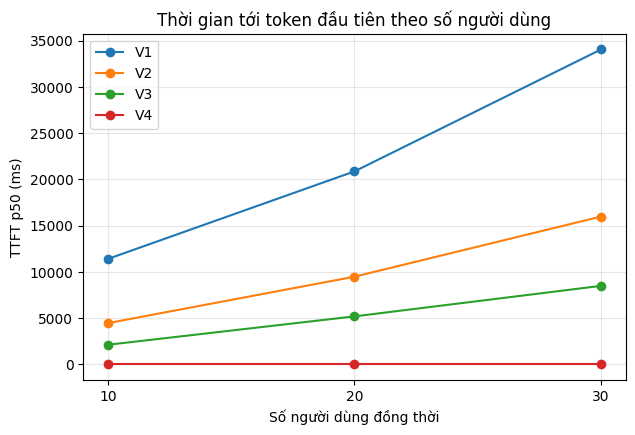

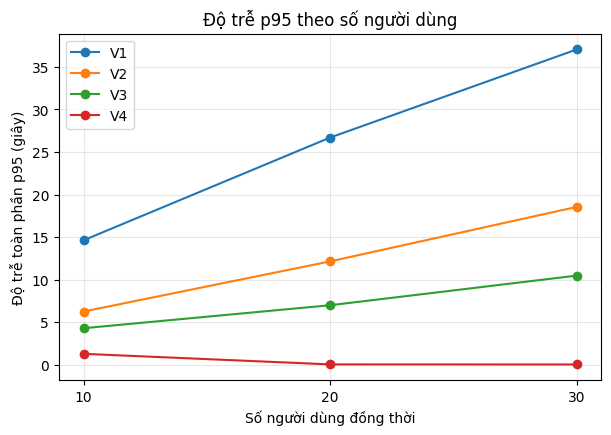

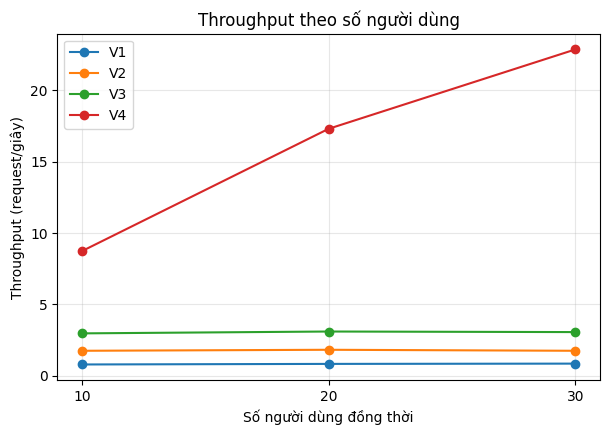

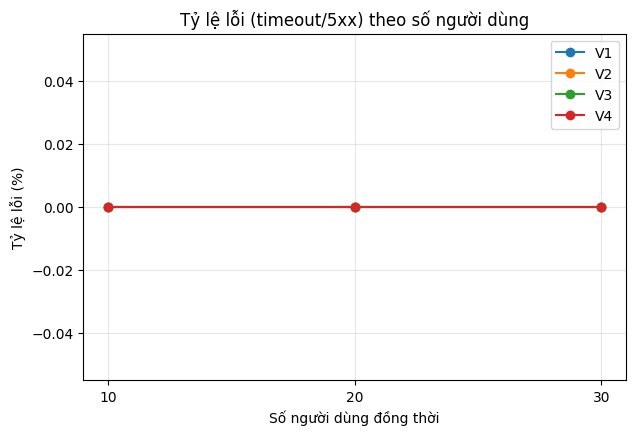

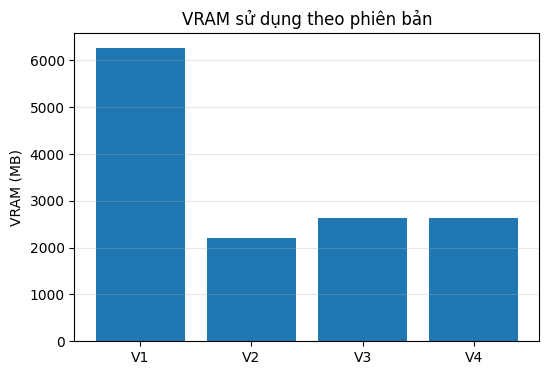

In [23]:
import matplotlib.pyplot as plt

table20 = results[results.users == 20][["version", "vram_mb", "ttft_p50_ms", "ttft_p95_ms", "rps",
                                        "error_pct", "reject429_pct", "cache_hit_pct"]].rename(columns={
    "version": "Phiên bản", "vram_mb": "VRAM (MB)", "ttft_p50_ms": "TTFT p50 (ms)", "ttft_p95_ms": "TTFT p95 (ms)",
    "rps": "Throughput (req/s)", "error_pct": "Lỗi timeout/5xx (%)", "reject429_pct": "Bị từ chối 429 (%)",
    "cache_hit_pct": "Cache hit (%)"})
table20.to_csv("/content/ket_qua/bang_so_sanh_20_users.csv", index=False)
print("BẢNG SO SÁNH Ở 20 NGƯỜI DÙNG ĐỒNG THỜI")
display(table20)

def line_plot(metric, ylabel, fname, title):
    plt.figure(figsize=(7, 4.5))
    for ver, g in results.groupby("version"):
        plt.plot(g["users"], g[metric], marker="o", label=ver)
    plt.xlabel("Số người dùng đồng thời"); plt.ylabel(ylabel); plt.title(title)
    plt.xticks(LEVELS); plt.grid(alpha=.3); plt.legend()
    plt.savefig(f"/content/ket_qua/{fname}", dpi=150, bbox_inches="tight"); plt.show()

line_plot("ttft_p50_ms", "TTFT p50 (ms)", "bieu_do_ttft.png", "Thời gian tới token đầu tiên theo số người dùng")
line_plot("lat_p95_s", "Độ trễ toàn phần p95 (giây)", "bieu_do_latency_p95.png", "Độ trễ p95 theo số người dùng")
line_plot("rps", "Throughput (request/giây)", "bieu_do_throughput.png", "Throughput theo số người dùng")
line_plot("error_pct", "Tỷ lệ lỗi (%)", "bieu_do_loi.png", "Tỷ lệ lỗi (timeout/5xx) theo số người dùng")

vr = results.groupby("version")["vram_mb"].mean()
plt.figure(figsize=(6, 4)); plt.bar(vr.index, vr.values)
plt.ylabel("VRAM (MB)"); plt.title("VRAM sử dụng theo phiên bản"); plt.grid(axis="y", alpha=.3)
plt.savefig("/content/ket_qua/bieu_do_vram.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
import numpy as np, pandas as pd
raw = pd.read_csv("/content/ket_qua/chi_tiet_tung_request.csv")
ok = raw[raw.status.astype(str) == "200"].copy()

# V4: tách request trúng cache và request chạy LLM thật
v4 = ok[ok.version == "V4"].copy()
v4["loai"] = np.where(v4.total < 0.1, "cache hit", "cache miss (chạy LLM thật)")
ket_qua_v4 = v4.groupby(["users", "loai"]).agg(
    so_request=("ttft", "size"),
    ttft_p50_ms=("ttft", lambda x: x.median() * 1000),
    ttft_p95_ms=("ttft", lambda x: x.quantile(.95) * 1000)).round(0)
print(ket_qua_v4)
ket_qua_v4.to_csv("/content/ket_qua/v4_hit_vs_miss.csv")

# Tỷ lệ request có TTFT dưới 3 giây (mục tiêu của đề bài)
ok["dat_duoi_3s"] = ok.ttft < 3
sla = (ok.groupby(["version", "users"]).dat_duoi_3s.mean() * 100).round(1)
print("\nTỷ lệ request có TTFT dưới 3 giây (%):")
print(sla)
sla.to_csv("/content/ket_qua/ty_le_duoi_3s.csv")

                                  so_request  ttft_p50_ms  ttft_p95_ms
users loai                                                            
10    cache hit                          730          2.0          5.0
      cache miss (chạy LLM thật)          56        585.0       2481.0
20    cache hit                         1486          2.0          4.0
      cache miss (chạy LLM thật)          70       2478.0       4387.0
30    cache hit                         1960          2.0          6.0
      cache miss (chạy LLM thật)          97       6663.0       8083.0

Tỷ lệ request có TTFT dưới 3 giây (%):
version  users
V1       10        2.6
         20        2.1
         30        1.0
V2       10        7.7
         20        1.7
         30        3.3
V3       10       84.1
         20        3.3
         30        2.3
V4       10       99.9
         20       98.4
         30       96.5
Name: dat_duoi_3s, dtype: float64


In [25]:
start_llama("q4", parallel=4)
start_gateway("V3-backpressure", max_queue=10, parallel=4, cache=False, stream=False)
warmup(); rds.flushdb()

df_bp = await run_load(40, 40, QUESTIONS)
kill("gw"); kill("llama")

df_bp["status"] = df_bp["status"].astype(str)
counts = df_bp.status.value_counts()
print(counts.to_string())
rej = df_bp[df_bp.status == "429"]
ok = df_bp[df_bp.status == "200"]
print(f"\nTỷ lệ bị từ chối 429: {100*len(rej)/len(df_bp):.1f}%")
print(f"Thời gian phản hồi của 429 (p50): {rej.total.median()*1000:.0f} ms  <- từ chối gần như tức thì")
print(f"Thời gian phản hồi của request thành công (p50): {ok.total.median():.2f} s")
df_bp.to_csv("/content/ket_qua/backpressure_429.csv", index=False)

status
429    904
200    119

Tỷ lệ bị từ chối 429: 88.4%
Thời gian phản hồi của 429 (p50): 3 ms  <- từ chối gần như tức thì
Thời gian phản hồi của request thành công (p50): 4.95 s


In [26]:
import shutil
from google.colab import files

shutil.copy("/content/gateway.py", "/content/ket_qua/gateway.py")
shutil.copy("/content/system_prompt.txt", "/content/ket_qua/system_prompt.txt")
shutil.make_archive("/content/ket_qua_nguoi2", "zip", "/content/ket_qua")
print(sorted(os.listdir("/content/ket_qua")))
files.download("/content/ket_qua_nguoi2.zip")

['backpressure_429.csv', 'bang_so_sanh_20_users.csv', 'bieu_do_latency_p95.png', 'bieu_do_loi.png', 'bieu_do_throughput.png', 'bieu_do_ttft.png', 'bieu_do_vram.png', 'chi_tiet_tung_request.csv', 'gateway.py', 'ket_qua_V1_V4.csv', 'luong_tu_hoa.csv', 'system_prompt.txt', 'ty_le_duoi_3s.csv', 'v4_hit_vs_miss.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>